# Análisis: preguntas de negocio y arquetipos de clientes

Este notebook usa las tablas limpias generadas por 01_limpieza.ipynb.

## 1. Carga de datos limpios

In [1]:
from pathlib import Path
import pandas as pd

RAIZ = Path.cwd().parent
PROC = RAIZ / "data" / "processed"
FIGS = RAIZ / "reports" / "figures"
DATA = RAIZ / "data"

archivos = ["customers", "orders", "order_items", "products"]
faltantes = [a for a in archivos if not (PROC / f"{a}.csv").exists()]
assert not faltantes, f"Faltan archivos en {PROC}: {faltantes}. Ejecuta primero 01_limpieza.ipynb"

customers   = pd.read_csv(PROC / "customers.csv",
                          parse_dates=["fecha_registro", "fecha_nacimiento", "primera_compra", "cliente_desde"])
orders      = pd.read_csv(PROC / "orders.csv", parse_dates=["fecha"])
order_items = pd.read_csv(PROC / "order_items.csv")
products    = pd.read_csv(PROC / "products.csv", parse_dates=["fecha_lanzamiento"])
stores = pd.read_csv(DATA / "stores.csv")  

FECHA_CORTE = pd.Timestamp("2026-09-30")

for nombre, df in {"customers": customers, "orders": orders, "order_items": order_items,
                   "products": products, "stores": stores}.items():
    print(f"{nombre}: {df.shape[0]} filas")

customers: 3005 filas
orders: 22651 filas
order_items: 47641 filas
products: 240 filas
stores: 5 filas


## 2. Tabla base de ventas

Se unen las líneas de venta con su orden, su producto y su cliente, y se calcula la venta neta de cada línea. Se aplican las definiciones de la limpieza:
- Solo cuentan como venta las órdenes completadas.
- Venta neta = cantidad × precio_unitario × (1 − descuento_pct / 100).
- El total de ventas de la marca incluye todas las ventas completadas; el análisis por cliente usa solo las órdenes atribuibles a un cliente registrado, sin cuentas internas.

In [3]:
ventas = (order_items
    .merge(orders, on="order_id", how="inner")
    .merge(products[["sku", "coleccion", "categoria", "fecha_lanzamiento"]], on="sku", how="left")
    .merge(customers[["customer_id", "cuenta_interna"]], on="customer_id", how="left")
    .merge(stores.rename(columns={"nombre": "tienda"}), on="tienda_id", how="left"))

ventas = ventas[ventas["es_venta"]].copy()
ventas["venta_neta"] = ventas["cantidad"] * ventas["precio_unitario"] * (1 - ventas["descuento_pct"] / 100)
ventas["cuenta_interna"] = ventas["cuenta_interna"].fillna(False).astype(bool)

# Ventas que se pueden asignar a un cliente real
ventas_cli = ventas[ventas["cliente_atribuible"] & ~ventas["cuenta_interna"]]

total_marca = ventas["venta_neta"].sum()
total_cli = ventas_cli["venta_neta"].sum()

print(f"Ventas netas de la marca: {total_marca:,.0f} MXN ({ventas['order_id'].nunique():,} órdenes)")
print(f"Ventas atribuibles a clientes: {total_cli:,.0f} MXN ({total_cli / total_marca:.1%})")
print(f"Clientes con al menos una compra: {ventas_cli['customer_id'].nunique():,}")

Ventas netas de la marca: 45,033,143 MXN (21,297 órdenes)
Ventas atribuibles a clientes: 42,247,804 MXN (93.8%)
Clientes con al menos una compra: 2,877


## 3. Pregunta 1: ¿quiénes se interesan por las nuevas colecciones?

### Verificación previa: ventas anteriores al lanzamiento del producto (P3)

Para medir el interés por lo nuevo hay que comparar la fecha de cada venta con la fecha de lanzamiento del producto. Antes se revisa que esa comparación tenga sentido: un producto no debería venderse antes de su lanzamiento.

In [7]:
ventas["dias_desde_lanz"] = (ventas["fecha"] - ventas["fecha_lanzamiento"]).dt.days
antes = ventas["dias_desde_lanz"] < 0

print("Líneas vendidas antes del lanzamiento:", antes.sum(), f"({antes.sum() / ventas['fecha_lanzamiento'].notna().sum():.2%})")
print("Clientes distintos:", ventas.loc[antes, "customer_id"].nunique())

ids_antes = ventas.loc[antes, "customer_id"].dropna().unique()
evento = customers.set_index("customer_id")["nota_evento_lanzamiento"]
print("De esos clientes, con nota de evento de lanzamiento:", int(evento.reindex(ids_antes).fillna(False).sum()), "de", int(evento.sum()))

(ventas[antes].groupby("coleccion")["dias_desde_lanz"]
   .agg(lineas="count", dias_min="min", dias_mediana="median", dias_max="max")
   .sort_values("lineas", ascending=False))

Líneas vendidas antes del lanzamiento: 1886 (5.84%)
Clientes distintos: 669
De esos clientes, con nota de evento de lanzamiento: 5 de 15


,lineas,dias_min,dias_mediana,dias_max
coleccion,,,,
PV24,1043,-45.0,-29.0,-1.0
OI26,291,-938.0,-403.0,-1.0
PV26,238,-770.0,-362.5,-1.0
OI25,151,-593.0,-240.0,-14.0
PV25,101,-379.0,-213.0,-1.0
OI24,62,-231.0,-108.5,-6.0


**Idea principal:** hay productos que aparecen vendidos antes de su fecha de lanzamiento, algo que no debería pasar. Son 1.886 líneas (5,8% de las ventas con colección), de 669 clientes. Esto significa que, para esas ventas, la colección que indica el catálogo no es confiable.

**Cómo leer la tabla:** dias_desde_lanz es la diferencia entre la fecha de la venta y la fecha de lanzamiento del producto. Un valor negativo significa que la venta ocurrió antes del lanzamiento.
- dias_min: la venta más lejana al lanzamiento (por ejemplo, −938 = vendida 938 días antes de que el producto existiera).
- dias_max: la venta más cercana al lanzamiento (−1 = vendida un día antes).
- dias_mediana: el valor típico; la mitad de las ventas anticipadas está por encima de ese valor y la otra mitad por debajo.

**Hay dos situaciones distintas:**

1. **PV24: 1.043 líneas, entre 1 y 45 días antes. Tiene explicación.** Los datos de órdenes empiezan el 2024-01-01, pero la primera colección del catálogo (PV24) se lanzó el 2024-02-15. Lo que se vendió en esas seis semanas eran productos de la temporada anterior, que no está en el catálogo; por eso aparecen con códigos de PV24.

2. **Resto de colecciones: 843 líneas, hasta 938 días antes. No tiene explicación de negocio.** Por ejemplo, hay productos de OI26 (lanzada en agosto de 2026) vendidos desde enero de 2024. Son casos aislados: las 291 líneas de OI26 están repartidas en más de dos años y equivalen a menos del 1% de lo que vendió la marca en ese periodo. Si fuera un comportamiento real, se verían ventas constantes de esos productos; en cambio, aparecen de forma esporádica. Lo más probable es un error en la fecha o en el SKU de esas órdenes.

**No es una preventa:** si fuera acceso anticipado para clientes especiales, serían pocos clientes y concentrados en las colecciones nuevas. En cambio, son 669 clientes, en todas las colecciones, y solo 5 de ellos asistieron a un evento de lanzamiento.

In [8]:
ventas["coleccion_valida"] = ventas["coleccion"].notna() & (
    ventas["coleccion"].eq("BASICOS") | (ventas["dias_desde_lanz"] >= 0))

# ventas_cli se recalcula para que también tenga las columnas nuevas
ventas_cli = ventas[ventas["cliente_atribuible"] & ~ventas["cuenta_interna"]]

print("Líneas con colección válida:", ventas["coleccion_valida"].sum(), "de", len(ventas))

Líneas con colección válida: 42849 de 44789


**Tratamiento:** se crea la bandera coleccion_valida. Las ventas anteriores al lanzamiento se mantienen en el total de ventas, pero no cuentan como compras de una colección.

**Impacto si no se corrige:** se contarían como compradores de una colección a clientes que compraron antes de que existiera. Además, todas las ventas de enero y febrero de 2024 se asignarían a PV24, inflando esa colección.

### ¿Cuánto dura el efecto de un lanzamiento?

Antes de definir la ventana de "compra de lanzamiento", se revisa cómo se distribuyen las ventas de cada colección según los días transcurridos desde su lanzamiento.

In [12]:
temp = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")]
semana = (temp["dias_desde_lanz"] // 7).clip(upper=26)

tabla_semanas = (temp.groupby(semana)["venta_neta"].sum()
                 .div(temp["venta_neta"].sum()).mul(100)
                 .rename("% ventas").to_frame())
tabla_semanas["% acumulado"] = tabla_semanas["% ventas"].cumsum()
tabla_semanas.index.name = "semana desde el lanzamiento"

tabla_semanas.round(1).head(26)

,% ventas,% acumulado
semana desde el lanzamiento,,
0.0,9.7,9.7
1.0,9.6,19.4
2.0,10.3,29.7
3.0,3.4,33.1
4.0,2.7,35.8
5.0,2.7,38.5
6.0,2.5,41.0
7.0,2.4,43.4
8.0,2.5,45.9


En las semanas 0, 1 y 2 se vende cerca del 10% de las ventas de temporada en cada una; desde la semana 3 el aporte cae a entre 2% y 3,5% semanal y se mantiene estable. Las primeras 3 semanas acumulan el 29,7% de las ventas de una colección, más que las 8 semanas siguientes juntas.

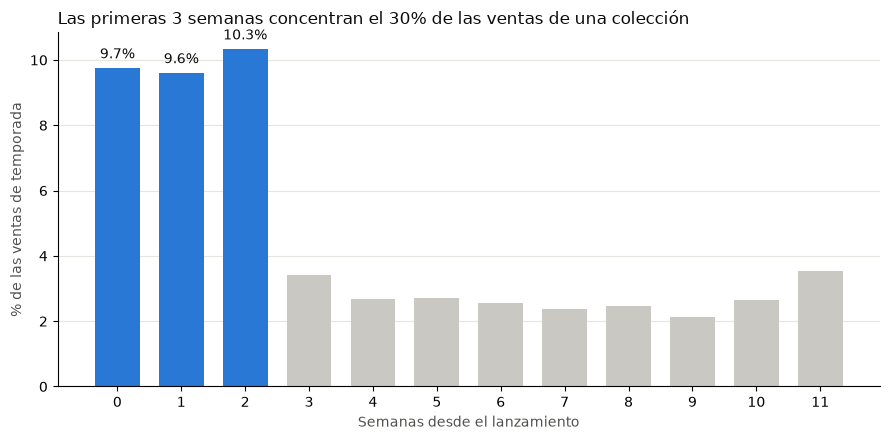

In [10]:
import matplotlib.pyplot as plt

temp = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")]
semana = temp["dias_desde_lanz"] // 7
dist = (temp.groupby(semana)["venta_neta"].sum() / temp["venta_neta"].sum() * 100).loc[0:11]

VENTANA_SEMANAS = 3
colores = ["#2a78d6" if s < VENTANA_SEMANAS else "#c9c8c2" for s in dist.index]

fig, ax = plt.subplots(figsize=(9, 4.5))
barras = ax.bar(dist.index, dist.values, color=colores, width=0.7)

# Etiqueta solo en las semanas del lanzamiento
for b, s in zip(barras, dist.index):
    if s < VENTANA_SEMANAS:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{b.get_height():.1f}%",
                ha="center", fontsize=10, color="#0b0b0b")

ax.set_title(f"Las primeras {VENTANA_SEMANAS} semanas concentran el "
             f"{dist.loc[:VENTANA_SEMANAS - 1].sum():.0f}% de las ventas de una colección",
             loc="left", fontsize=12, color="#0b0b0b")
ax.set_xlabel("Semanas desde el lanzamiento", color="#52514e")
ax.set_ylabel("% de las ventas de temporada", color="#52514e")
ax.set_xticks(dist.index)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e6e5e0", linewidth=0.8)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig(FIGS / "q1_ventana_lanzamiento.png", dpi=200, bbox_inches="tight")
plt.show()

La caída es abrupta y ocurre justo en la semana 3: el efecto del lanzamiento dura unas 3 semanas, no se desvanece poco a poco. Por eso se define la ventana de lanzamiento en 21 días: una compra de un producto de temporada dentro de ese periodo indica interés por lo nuevo; una compra posterior es una compra de temporada normal.

### Criterio

Un cliente se interesa por las nuevas colecciones si compra productos de temporada (no BASICOS) durante la ventana de lanzamiento: los primeros 21 días después de que sale la colección (semanas 0, 1 y 2). Comprar un producto meses después de su lanzamiento no muestra interés por lo nuevo; comprarlo en el lanzamiento, sí.

- **Interesado:** compró en el lanzamiento de 1 colección.
- **Muy interesado:** compró en el lanzamiento de 2 o más colecciones; el interés se repite y no es casualidad.

In [13]:
VENTANA_DIAS = 21

col = ventas_cli[ventas_cli["coleccion_valida"] & (ventas_cli["coleccion"] != "BASICOS")].copy()
col["compra_lanzamiento"] = (col["dias_desde_lanz"] >= 0) & (col["dias_desde_lanz"] < VENTANA_DIAS)

# Por cliente: en cuántos lanzamientos compró y cuánto gastó en ellos
lanz = (col[col["compra_lanzamiento"]].groupby("customer_id")
        .agg(colecciones_lanz=("coleccion", "nunique"), venta_lanz=("venta_neta", "sum")))

clientes = ventas_cli.groupby("customer_id").agg(venta_total=("venta_neta", "sum"))
clientes = clientes.join(lanz).fillna({"colecciones_lanz": 0, "venta_lanz": 0})

clientes["nivel_novedad"] = pd.cut(clientes["colecciones_lanz"], bins=[-1, 0, 1, float("inf")],
                                   labels=["Sin interés", "Interesado", "Muy interesado"])

resumen_q1 = (clientes.groupby("nivel_novedad", observed=True)
              .agg(clientes=("venta_total", "size"), venta_total=("venta_total", "sum"), venta_lanz=("venta_lanz", "sum")))
resumen_q1["% clientes"] = (resumen_q1["clientes"] / resumen_q1["clientes"].sum() * 100).round(1)
resumen_q1["% ventas marca"] = (resumen_q1["venta_total"] / total_marca * 100).round(1)
resumen_q1

,clientes,venta_total,venta_lanz,% clientes,% ventas marca
nivel_novedad,,,,,
Sin interés,2158,16230693.00,0.00,75.0,36.0
Interesado,238,2499352.95,637329.20,8.3,5.6
Muy interesado,481,23517758.45,8553895.85,16.7,52.2


In [14]:
validacion = clientes.join(customers.set_index("customer_id")[["nota_evento_lanzamiento"]])
print(pd.crosstab(validacion["nivel_novedad"], validacion["nota_evento_lanzamiento"],
                  margins=True, margins_name="Total"))

nota_evento_lanzamiento  False  True  Total
nivel_novedad                              
Sin interés               2144    14   2158
Interesado                 237     1    238
Muy interesado             481     0    481
Total                     2862    15   2877


In [15]:
ids_evento = customers.loc[customers["nota_evento_lanzamiento"], "customer_id"]
ev = ventas_cli[ventas_cli["customer_id"].isin(ids_evento)]

print("Clientes con nota de evento que compraron algo:", ev["customer_id"].nunique(), "de", len(ids_evento))
print("Compras de temporada por momento respecto al lanzamiento:")
momento = pd.cut(ev["dias_desde_lanz"], bins=[-10_000, -1, 20, 10_000],
                 labels=["Antes del lanzamiento", "Ventana (0–20 días)", "Después de la ventana"])
print(momento.value_counts().to_string())
print("\nLíneas de BASICOS:", (ev["coleccion"] == "BASICOS").sum())

Clientes con nota de evento que compraron algo: 15 de 15
Compras de temporada por momento respecto al lanzamiento:
dias_desde_lanz
Después de la ventana    54
Antes del lanzamiento    10
Ventana (0–20 días)       3

Líneas de BASICOS: 113


### Validación con las notas del CRM

Se esperaba que los 15 clientes con la nota "Registro en evento de lanzamiento" aparecieran como interesados o muy interesados. No es así: 14 quedaron en "Sin interés". Al revisar sus compras, los 15 sí compran, pero principalmente productos BASICOS (113 líneas), y sus compras de temporada ocurren casi siempre después de la ventana de lanzamiento (54 líneas, frente a 3 dentro de ella).

**Conclusión:** la nota indica que el cliente se registró durante un evento, no que compre novedades. El criterio basado en el comportamiento de compra es más confiable que una nota de texto libre presente en solo 15 clientes.

**Oportunidad:** los eventos de lanzamiento están captando clientes de básicos. Los 481 clientes "muy interesados", que generan el 52% de las ventas de la marca, serían el público natural para invitar a esos eventos.

### Respuesta a la pregunta 1

- **481 clientes (16,7%) son "muy interesados"**: compraron en el lanzamiento de 2 o más colecciones. Generan el **52,2% de las ventas de la marca**, y no solo compran en el lanzamiento: de sus 23,5 millones de MXN, unos 8,6 millones corresponden a la ventana de lanzamiento y el resto a compras durante la temporada.
- **238 clientes (8,3%) son "interesados"**: compraron en un solo lanzamiento; generan el 5,6% de las ventas.
- **2.158 clientes (75%) no compran en los lanzamientos** y generan el 36% de las ventas.

Las novedades atraen a un grupo pequeño de clientes que concentra más de la mitad del negocio.